<center>
    <h2>Master 2</h2>
    <h5 style="margin-top: 5px">Sciences de l’Océan, de l’Atmosphère et du Climat</h5>
    <h1>TP - Système climatique</h1>
  <br>
    <strong>Contact:</strong> isaline.bossert@meteo.fr / romain.torres4@gmail.com

</center>


<div style="padding: 1rem; background-color: #d1ecf1; border: 1px solid #bee5eb; border-radius: 4px; margin: 1rem 0;">
  <strong>💡 Instructions</strong> 
    
Ce notebook est à <i>compléter</i> avec vos réponses aux questions posées et à <i>envoyer</i> par mail au plus tard <u>une semaine après la dernière séance de TP</u>. Merci de renommer le notebook pour y incorporer vos noms de famille (ex: TP-Climat-2026-Nom1_Nom2_Nom3.ipynb)
  - une attention particulière doit être donnée aux <b>figures</b> (clareté, titre, axes, légendes, etc..) 
  - les analyses portent sur vos <b>connaissances théoriques</b> en lien avec le cours "Système Climatique" (J. Cattiaux) sont attendues
  - la <b>curiosité scientifique</b> est bien sûre encouragée: même si les questions sont là pour aiguiller le TP, n'hésitez pas à demander des clarifications où d'éventuelles pistes d'analyses supplémentaires ;)
    

⚠️ Lors de la dernière séance, chaque groupe présentera son notebook (sujet + analyses effectuées):
  - durée max de 12 minutes de restitution qui doit être <b>claire</b> et <b>synthétique</b>. Il n'est pas nécessaire de créer un support de présentation particulier.
  - la restitution est suivie d'un <b>tour de questions</b> de la part des élèves puis des enseignantes pour vérifier les notions

<center>
        <h1>Sujet 4: <br>Projection climatique et incertitudes</h1>
  <br>
    <strong>Main topics covered here:</strong>
    <br>
    Projections and uncertainties (c.f. Cours 5)
    <br>
    Internal variability (c.f. Cours 2) 

</center>

## Introduction

Current climate change is primarily driven by the concentrations of greenhouse gases in the atmosphere, which are themselves a result of human activities. Hence, projections of future climate change for the next decades are based on different scenarios of greenhouse gases concentrations, reflecting different socio-economic pathways under several hypitheses (demographic, economic, politics, technologic, etc.). In the last IPCC assessment report [(IPCC AR6)](https://www.ipcc.ch/assessment-report/ar6/), these scenarios are called the _Shared Socioeconomic Pathways_ (SSP) and are classified in five distinct categories from SSP1 to SSP5 ([Fig. 1](#tp4-fig1)). Each category is declined in a suite of scenarios characterized by the end of century radiative forcing (e.g. 2.6, 4.5 and 8.5 W.m$^{-2}$ for SSP1-2.6, SSP2-4.5 and SSP5-8.5, respectively).

Climate models are then used to simulated climate evolution during the 21th century (and even further) for each scenario. Accuracy of these climate projections is function of three different factors ([Fig. 2](#tp4-fig2)):
1. **<span style="color: green;">scenario uncertainty</span>** driven by the choice in SSP scenarios, which alter the concentration of greenhouse gases and anthropic aerosols in the atmopshere resulting in different external focing. 
2. **<span style="color: blue;">model uncertainty</span>**, which quantifies modelling error in simulating the climate responses to external forcing, both from natural (solar radiation, volcanic aerosols, etc.) and anthropic sources.
3. **<span style="color: orange;">internal variability</span>** related to uding chaotic fluctuations of the climate dynamical system when subject to a constant or periodic external forcing (such as the annual cycle).


In this notebook, you will analyze climate projections from a suite of 20 CMIP6 climate models under three SSP (Shared Socio-Economic Pathway): SSP1-2.6, SSP2-4.5, SSP5-8.5. In particular, you will:
  - part 1: SSPs
  - part 2: Uncertainty on the global mean surface temperature
  - part 3: Other variables / regions
  - part 4: RCMs vs GCMs


<br>

<div align="center">
    <div id="tp4-fig1" style="width: 550px; float: left">
        <img src="../figures/IPCC-AR6-SPM-Fig3.png" alt="drawing" width="500"/>
    </div>
    <div id="tp4-fig2" style="width: 300px; float right">
        <br><br><br><br>
        <img src="../figures/Hawkins_and_Sutton-2009-Fig4.png" alt="drawing" width="400"/>
    </div>
    <br>
    <div>
    <div style="width: 550px; float: left">
    <b>Fig. 1. </b>Global surface temperature changes relative to 1850-1900 for five different shared socioeconomic pathways (SSPs). Taken from <a href="https://www.ipcc.ch/report/ar6/wg2/figures/summary-for-policymakers/">IPCC AR6 - SPM</a>.
    </div>
    <div style="width: 300px; float right">
    <b>Fig. 2. </b>The fraction of total variance in decadal mean surface air temperature predictions explained by the three components of total uncertainty for the global mean. Green regions represent scenario uncertainty, blue regions represent model uncertainty, and orange regions represent the internal variability component. Taken from <a href="https://doi.org/10.1175/2009BAMS2607.1">Hawkins and Sutton (2009)</a>.
    </div>
    </div>
</div>

<br><br><br><br>

## Load Python modules and simulation outputs

Along this notebook, Python codes are used to analyse model outputs.
You first need to import and load required modules:

In [1]:
# manipulate file and data
import os
import numpy  as np
import pandas as pd
import xarray as xr
import scipy

# plotting
import matplotlib
import matplotlib.pyplot as plt

The code below loads results from 20 CMIP6 climate models for scenarios SSP1-2.6, SSP2-4.5 and SSP5-8.5.

In [2]:
# initialize empty dict to store variables
ssp126 = dict()
ssp245 = dict()
ssp585 = dict()


# load 20 models in csv (.asc) files using pandas and convert into xarray.Dataset
df = pd.read_csv('../data/'+"T_Glo_ANN_ssp126.asc", sep=" ")-273.15
ssp126['ts'] = xr.DataArray(data=df.values,
                            dims=('year', 'model'),
                            coords={'year': np.array(df.index), 'model': np.array(df.columns)}
                           )

df = pd.read_csv('../data/'+"T_Glo_ANN_ssp245.asc", sep=" ")-273.15
ssp245['ts'] = xr.DataArray(data=df.values,
                            dims=('year', 'model'),
                            coords={'year': np.array(df.index), 'model': np.array(df.columns)}
                           )

df = pd.read_csv('../data/'+"T_Glo_ANN_ssp585.asc", sep=" ")-273.15
ssp585['ts'] = xr.DataArray(data=df.values,
                            dims=('year', 'model'),
                            coords={'year': np.array(df.index), 'model': np.array(df.columns)}
                           )

# load some model outputs with precip in csv (.asc)
df = pd.read_csv('../data/'+"Pr_Glo_ANN_ssp126.asc", sep=" ", index_col=0)
ssp126['pr'] = xr.DataArray(data=df.values,
                            dims=('year', 'model'),
                            coords={'year': np.array(df.index), 'model': np.array(df.columns)}
                           )

df = pd.read_csv('../data/'+"Pr_Glo_ANN_ssp245.asc", sep=" ", index_col=0)
ssp245['pr'] = xr.DataArray(data=df.values,
                            dims=('year', 'model'),
                            coords={'year': np.array(df.index), 'model': np.array(df.columns)}
                           )

df = pd.read_csv('../data/'+"Pr_Glo_ANN_ssp585.asc", sep=" ", index_col=0)
ssp585['pr'] = xr.DataArray(data=df.values,
                            dims=('year', 'model'),
                            coords={'year': np.array(df.index), 'model': np.array(df.columns)}
                           )

# add CO2 emissions for each scenario
ar = np.loadtxt('../data/CO2/SSPs-CO2_emissions.csv', skiprows=1)
ssp126['co2_emissions'] = xr.DataArray(data=ar[:,1], dims=('year'), coords={'year': ar[:,0]})
ssp245['co2_emissions'] = xr.DataArray(data=ar[:,2], dims=('year'), coords={'year': ar[:,0]})
ssp585['co2_emissions'] = xr.DataArray(data=ar[:,3], dims=('year'), coords={'year': ar[:,0]})

print("Models loaded for 'ts': \n", list(ssp126['ts']['model'].data))
print("")
print("Models loaded for 'pr': \n", list(ssp126['pr']['model'].data))

Models loaded for 'ts': 
 ['ACCESS-CM2', 'MPI-ESM1-2-HR', 'UKESM1-0-LL', 'ACCESS-ESM1-5', 'CESM2-WACCM', 'INM-CM4-8', 'MPI-ESM1-2-LR', 'FGOALS-f3-L', 'INM-CM5-0', 'MRI-ESM2-0', 'CNRM-CM6-1-HR', 'IPSL-CM6A-LR', 'NorESM2-LM', 'CNRM-CM6-1', 'GISS-E2-1-G', 'MIROC6', 'NorESM2-MM', 'CNRM-ESM2-1', 'HadGEM3-GC31-LL', 'MIROC-ES2L']

Models loaded for 'pr': 
 ['ACCESS-CM2', 'EC-Earth3-Veg-LR', 'UKESM1-0-LL', 'CanESM5-CanOE', 'CMCC-ESM2', 'INM-CM4-8', 'MPI-ESM1-2-LR', 'FGOALS-f3-L', 'INM-CM5-0', 'MRI-ESM2-0', 'CNRM-CM6-1-HR', 'IPSL-CM6A-LR', 'NorESM2-LM', 'CNRM-CM6-1', 'GFDL-ESM4', 'MIROC6', 'NorESM2-MM', 'CNRM-ESM2-1', 'HadGEM3-GC31-LL', 'MIROC-ES2L']


Here, the global mean surface temperature (GMST) is available in three python dictionnaries `ssp126`, `ssp245` and `ssp585`.
You can access to the data, by using the variable name:

```python
    ssp126['ts']            # this return an xarray.DataArray object
    ssp126['ts'].data       # this return an numpy.array object
    ssp126['ts']['year']    # this return the 'year' coordinate for the variable 'ts'
```

In addition, we loaded CO$_2$ emissions combined from historical inventory and SSP scenarios:

```python
    ssp126['co2_emissions']  # this return an xarray.DataArray object
```

<a id="section-1"></a>
## 1. Shared Socioeconomics Pathways 

We first take a look into the trajectory of the three selected Shared Socioeconomic Pathways (SSPs): SSP1-2.6, SSP2-4.5 and SSP5-8.5. 

#### Question 1

* _Plot the time-series for CO$_2$ emissions in the three SSPs._
* _What do you see ?_


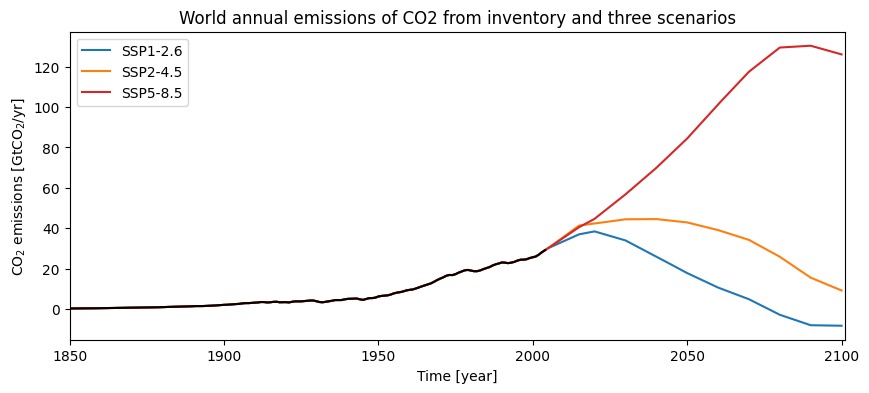

In [3]:
# plot
fig, ax = plt.subplots(1,1, figsize=(10, 4))

ax.plot( ssp126['co2_emissions']['year'], 1e-9*ssp126['co2_emissions'], label='SSP1-2.6', c='tab:blue')
ax.plot( ssp245['co2_emissions']['year'], 1e-9*ssp245['co2_emissions'], label='SSP2-4.5', c='tab:orange')
ax.plot( ssp585['co2_emissions']['year'], 1e-9*ssp585['co2_emissions'], label='SSP5-8.5', c='tab:red')
ax.plot( ssp126['co2_emissions']['year'][:155], 1e-9*ssp126['co2_emissions'][:155],       c='k')

# axe properties
ax.set_xlabel('Time [year]')
ax.set_ylabel(r'CO$_2$ emissions [GtCO$_2$/yr]')

ax.set_xlim((1850, 2101))

ax.legend()

_ = ax.set_title("World annual emissions of CO2 from inventory and three scenarios")

<font color="blue">

- emissions have increased exponentially since 1950
- the 3 scenarios show different trajectory; it is worthnoting that SSP1-2.6 requires negative emissions to reach a low level of radiative forcing in 2100.
- Covid pandemic not seen here, seens the inventory ends in 2005
    
</font>

#### Question 2

* _Plot the time-series for global mean surface temperature (GMST) in the three SSPs._

__Help:__ remember that 20 models are used, all of them having a different pre-industrial global mean surface temperature level. It is therefore more convenient to work with anomalies of GMST $\Delta T_s$.

To avoid too much lines in your graph you can either split in several plots or use the functions [xarray.mean](https://docs.xarray.dev/en/stable/generated/xarray.DataArray.mean.html) and [xarray.std](https://docs.xarray.dev/en/stable/generated/xarray.DataArray.std.html) to characterize each scenario.

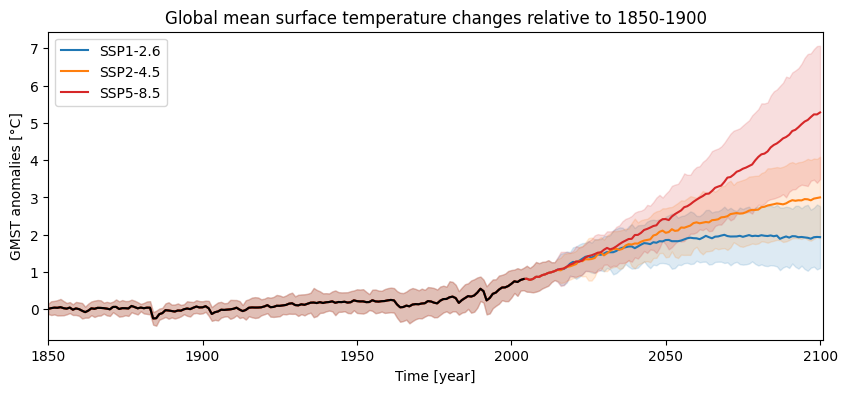

In [4]:
# plot
fig, ax = plt.subplots(1,1, figsize=(10, 4))

# compute GMST anomalies
ssp126['tsa'] = (ssp126['ts'] - ssp126['ts'].isel({'year': slice(0, 50)}).mean('year'))
ssp245['tsa'] = (ssp245['ts'] - ssp245['ts'].isel({'year': slice(0, 50)}).mean('year'))
ssp585['tsa'] = (ssp585['ts'] - ssp585['ts'].isel({'year': slice(0, 50)}).mean('year'))

# get mean and std for each scenario
mean126 = ssp126['tsa'].mean('model')
std126  = ssp126['tsa'].std('model')

mean245 = ssp245['tsa'].mean('model')
std245  = ssp245['tsa'].std('model')

mean585 = ssp585['tsa'].mean('model')
std585  = ssp585['tsa'].std('model')

# plot multi-model mean
ax.plot( ssp126['ts']['year'], mean126,         label='SSP1-2.6', lw=1.5, c='tab:blue')
ax.plot( ssp245['ts']['year'], mean245,         label='SSP2-4.5', lw=1.5, c='tab:orange')
ax.plot( ssp585['ts']['year'], mean585,         label='SSP5-8.5', lw=1.5, c='tab:red')
ax.plot( ssp126['ts']['year'][:155], ssp126['tsa'].mean('model')[:155],   c='k')

# plot range
ax.fill_between( ssp126['ts']['year'], mean126+1.64*std126, mean126-1.64*std126, color='tab:blue',   alpha=0.15)
ax.fill_between( ssp245['ts']['year'], mean245+1.64*std245, mean245-1.64*std245, color='tab:orange', alpha=0.15)
ax.fill_between( ssp585['ts']['year'], mean585+1.64*std585, mean585-1.64*std585, color='tab:red',    alpha=0.15)

# axe properties
ax.set_xlabel('Time [year]')
ax.set_ylabel(r'GMST anomalies [°C]')

ax.set_xlim((1850, 2101))

ax.legend(loc=2)

_ = ax.set_title("Global mean surface temperature changes relative to 1850-1900")

<font color="blue">

- Discuss how the spread changes with time and with scenarios; why ?
    
- There is a correlation between warming and CO$_2$ emiisions
    
- $\Delta T_s$ in SSP2-4.5 still increases during all the 21th century even if CO$_2$ emissions decreases from year 2040.
    
- in the historical periods, there are some very rapid changes in temperature due to natural volcanic aerosols (external forcing) that tends to cool the climate
    
- scenario uncertainty is evident from 2050 to 2100; model uncertainty + internal variavility are shown with the 1.64$\sigma$ spread
    
</font>

#### Question 3 

* _Combine the two previous metrics by plotting temperature change against cummulative CO$_2$ emissions._
* _How do you intepret the figure ?_

__Help:__ you can compute cummulative emissions with the [xarray.cumsum](https://docs.xarray.dev/en/stable/generated/xarray.DataArray.cumsum.html) function.

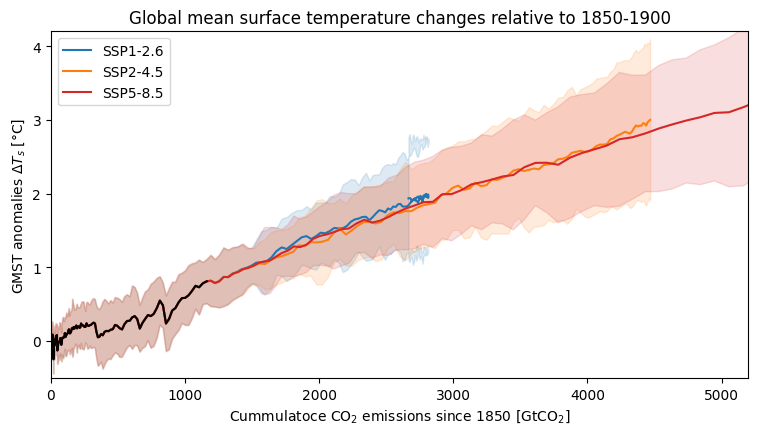

In [5]:
# plot
fig, ax = plt.subplots(1,1, figsize=(9, 4.5))

# get cummulative sum of CO2 emissions
cum_co2_ssp126 = 1e-9*ssp126['co2_emissions'].cumsum('year')
cum_co2_ssp245 = 1e-9*ssp245['co2_emissions'].cumsum('year')
cum_co2_ssp585 = 1e-9*ssp585['co2_emissions'].cumsum('year')

# plot multi-model mean against cummulative CO2
ax.plot( cum_co2_ssp126, mean126,         label='SSP1-2.6', lw=1.5, c='tab:blue')
ax.plot( cum_co2_ssp245, mean245,         label='SSP2-4.5', lw=1.5, c='tab:orange')
ax.plot( cum_co2_ssp585, mean585,         label='SSP5-8.5', lw=1.5, c='tab:red')
ax.plot( cum_co2_ssp126[:155], ssp126['tsa'].mean('model')[:155],   c='k')

# plot range
ax.fill_between( cum_co2_ssp126, mean126+1.64*std126, mean126-1.64*std126, color='tab:blue',   alpha=0.15)
ax.fill_between( cum_co2_ssp245, mean245+1.64*std245, mean245-1.64*std245, color='tab:orange', alpha=0.15)
ax.fill_between( cum_co2_ssp585, mean585+1.64*std585, mean585-1.64*std585, color='tab:red',    alpha=0.15)

# axe properties
ax.set_xlabel('Cummulatoce CO$_2$ emissions since 1850 [GtCO$_2$]')
ax.set_ylabel(r'GMST anomalies $\Delta T_s$ [°C]')

ax.set_xlim((0, 5200))
ax.set_ylim((-0.5, 4.2))

ax.legend(loc=2)

_ = ax.set_title("Global mean surface temperature changes relative to 1850-1900")

<font color="blue">

- we retrieve the well known quasi linear relationship between $\Delta T_s$ and CO$_2$ emissions 
    
</font>

#### Question 4

* _Plot the time-series for global averaged precipitation in the three SSPs._
* _Can you find a correlation with another variable ? Why ?_

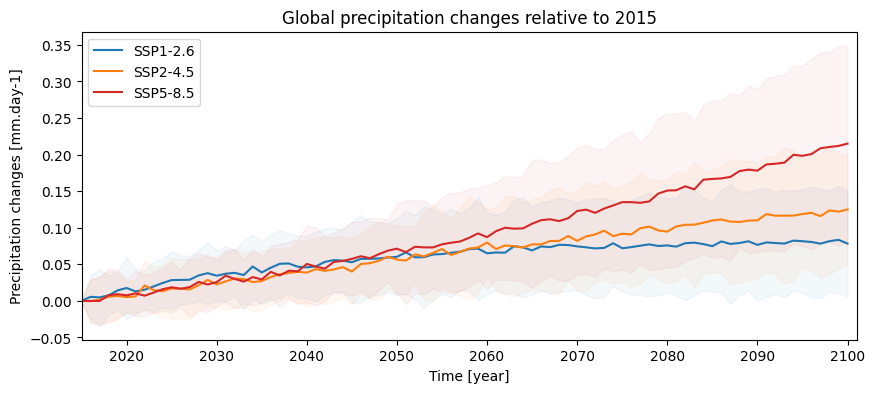

In [6]:
# plot
fig, ax = plt.subplots(1,1, figsize=(10, 4))

# compute precipitation anomalies
ssp126['pra'] = (ssp126['pr'] - ssp126['pr'].isel({'year': 0}))
ssp245['pra'] = (ssp245['pr'] - ssp245['pr'].isel({'year': 0}))
ssp585['pra'] = (ssp585['pr'] - ssp585['pr'].isel({'year': 0}))

# get mean and std for each scenario
mean126_pr = ssp126['pra'].mean('model')
std126_pr  = ssp126['pra'].std('model')

mean245_pr = ssp245['pra'].mean('model')
std245_pr  = ssp245['pra'].std('model')

mean585_pr = ssp585['pra'].mean('model')
std585_pr  = ssp585['pra'].std('model')

# plot multi-model mean
ax.plot( ssp126['pr']['year'], mean126_pr,         label='SSP1-2.6', lw=1.5, c='tab:blue')
ax.plot( ssp245['pr']['year'], mean245_pr,         label='SSP2-4.5', lw=1.5, c='tab:orange')
ax.plot( ssp585['pr']['year'], mean585_pr,         label='SSP5-8.5', lw=1.5, c='tab:red')

# plot range
ax.fill_between( ssp126['pr']['year'], mean126_pr+1.64*std126_pr, mean126_pr-1.64*std126_pr, 
                                                                    color='tab:blue',   alpha=0.05)
ax.fill_between( ssp245['pr']['year'], mean245_pr+1.64*std245_pr, mean245_pr-1.64*std245_pr, 
                                                                    color='tab:orange', alpha=0.05)
ax.fill_between( ssp585['pr']['year'], mean585_pr+1.64*std585_pr, mean585_pr-1.64*std585_pr, 
                                                                    color='tab:red',    alpha=0.05)

# axe properties
ax.set_xlabel('Time [year]')
ax.set_ylabel(r'Precipitation changes [mm.day-1]')

ax.set_xlim((2015, 2101))

ax.legend(loc=2)

_ = ax.set_title("Global precipitation changes relative to 2015")

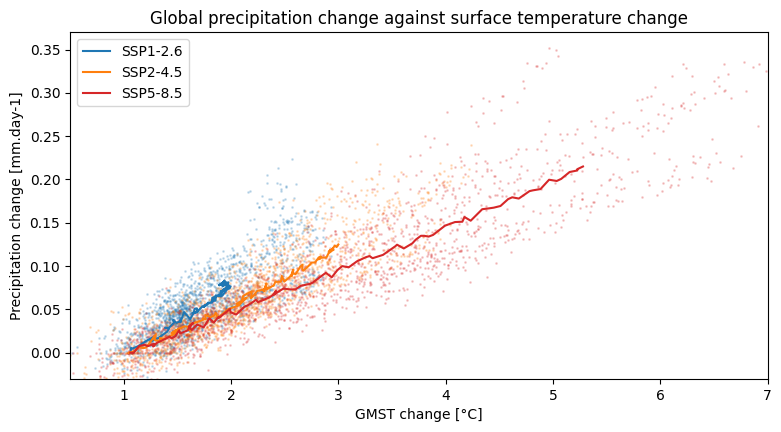

In [7]:
# plot
fig, ax = plt.subplots(1,1, figsize=(9, 4.5))

# compute precipitation anomalies
ssp126['pra'] = (ssp126['pr'] - ssp126['pr'].isel({'year': 0}))
ssp245['pra'] = (ssp245['pr'] - ssp245['pr'].isel({'year': 0}))
ssp585['pra'] = (ssp585['pr'] - ssp585['pr'].isel({'year': 0}))

# get mean and std for each scenario
mean126_pr = ssp126['pra'].mean('model')
std126_pr  = ssp126['pra'].std('model')

mean245_pr = ssp245['pra'].mean('model')
std245_pr  = ssp245['pra'].std('model')

mean585_pr = ssp585['pra'].mean('model')
std585_pr  = ssp585['pra'].std('model')

# plot multi-model mean
ax.plot( mean126.sel({'year': slice(2015,2101)}), mean126_pr, lw=1.5, label='SSP1-2.6', c='tab:blue')
ax.plot( mean245.sel({'year': slice(2015,2101)}), mean245_pr, lw=1.5, label='SSP2-4.5', c='tab:orange')
ax.plot( mean585.sel({'year': slice(2015,2101)}), mean585_pr, lw=1.5, label='SSP5-8.5', c='tab:red')

ax.scatter( ssp126['tsa'].sel({'year': slice(2015,2101)}), ssp126['pra'], s=1, alpha=0.2, c='tab:blue')
ax.scatter( ssp245['tsa'].sel({'year': slice(2015,2101)}), ssp245['pra'], s=1, alpha=0.2, c='tab:orange')
ax.scatter( ssp585['tsa'].sel({'year': slice(2015,2101)}), ssp585['pra'], s=1, alpha=0.2, c='tab:red')


# axe properties
ax.set_xlabel('GMST change [°C]')
ax.set_ylabel(r'Precipitation change [mm.day-1]')

ax.set_xlim((0.5, 7))
ax.set_ylim((-0.03, 0.37))

ax.legend(loc=2)

_ = ax.set_title("Global precipitation change against surface temperature change")

<font color="blue">

- **Modification of the global hydrological cycle.**

  - CLausius-Clapeyron: warmer atmosphere = water vapour in its constitution; in turn this leads to more evaporation/precipitation (intensification of the hydrological cycle)
    
  - the relation is linear with $\Delta T_s$ (and thus with cummulative CO$_2$)
    
</font>

<a id="section-2"></a>
## 2. Partitioning uncertainty

In this section, we will estimate the three uncertainty sources of climate projections, that come from <span style="color: green;">scenarios</span>, <span style="color: blue;">models</span> and <span style="color: orange;">internal variability</span>.

We will first try to extract the internal variability from the projection data sets. To do so, each prediction of the variable $X$ for a given model $m$, scenario $s$ and time $t$ is decomposed as a sum of several variability sources: 

$$ X(t, m, s) = x(t, m, s) + i(m, s) + \epsilon(t, m, s) $$

- $x$ is the response to external forcing (increase in the greenhouse gases concentration, variations of concentration in anthropogenic and natural aerosols, fluctuations in solar variability or volcanic eruptions and land‐use changes). In practice, it is evaluated as the smooth fit of $X$ on the total period in order to filter the internal variability component.
- $i$ is a reference value that depend to each model and scenario, which vanishes when dealing with anomalies. 
- the residual $\epsilon$ thus corresponds to the estimation of the internal variability.


The total uncertainty $T$ is then given by the sum of the three uncertainty sources:

$$ T(t) = \color{orange}{V} + \color{blue}{M(t)} + \color{green}{S(t)}$$
with :

- the uncertainty due to the internal variability $\color{orange}{V}$, considering as a constant, that means constant in time and independent of the scenario. We can thus define it from the variance of $\epsilon$ (and then by taking the multi-model mean of the variance):
$$\color{orange}{V = \frac{1}{N_{mod}} \sum_{m=1}^{N_{mod}} \textrm{Var}_{t,s}[\epsilon(m)]}$$
where $N_{mod}$ is the number of models.


- the model uncertainty $\color{blue}{M}$ that represents the different responses $x$ simulated by the different models. The multiscenario mean is taken as an estimate of the model uncertainty:
$$\color{blue}{M(t) = \frac{1}{N_{scen}} \sum_{s=1}^{N_{scen}} \textrm{Var}_{m}[x(t,s)]}$$
where $N_{scen}$ is the number of scenarios.


- the scenario uncertainty  $\color{blue}{S}$ is simply the variance of the multimodel means for the three scenarios:io mean is taken as an estimate of the model uncertainty:
$$\color{green}{S(t) = \textrm{Var}_{scen}\left[\frac{1}{N_{mod}} \sum_{m=1}^{N_{mod}} x(t,m)\right]}$$

#### Question 5

We will start by filtering the internal variability from the time-series of global mean surface temperature (GMST).

* _Choose one model and plot the time-series for global mean surface temperature (GMST) in the three SSPs._
* _Then, estimate the forced response of the selected model by smoothing time-series with a polynomial fit._

__Help:__ polynomial fit can be done in python with the [numpy Polynomial](https://numpy.org/doc/stable/reference/generated/numpy.polynomial.polynomial.Polynomial.fit.html#numpy.polynomial.polynomial.Polynomial.fit) class. Try several degrees and choose the one which works best.

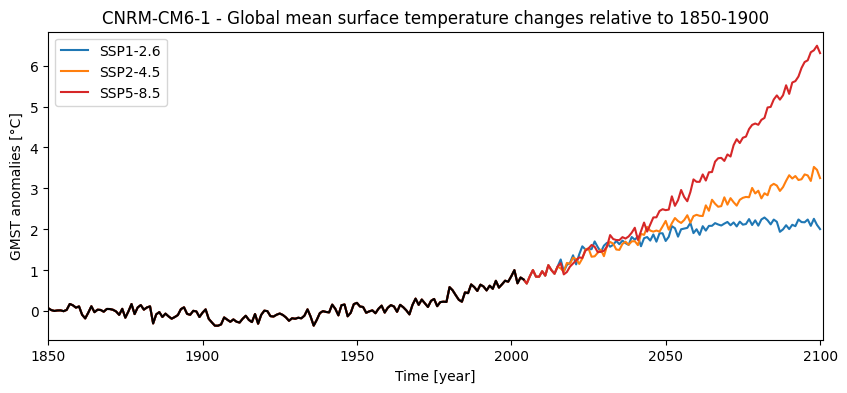

In [8]:
# plot
fig, ax = plt.subplots(1,1, figsize=(10, 4))

# choose one model
model = 'CNRM-CM6-1'

# plot model time-series
ax.plot( ssp126['ts']['year'], ssp126['tsa'].sel({'model': model}), label='SSP1-2.6', lw=1.5, c='tab:blue')
ax.plot( ssp245['ts']['year'], ssp245['tsa'].sel({'model': model}), label='SSP2-4.5', lw=1.5, c='tab:orange')
ax.plot( ssp585['ts']['year'], ssp585['tsa'].sel({'model': model}), label='SSP5-8.5', lw=1.5, c='tab:red')
ax.plot( ssp126['ts']['year'][:155], ssp126['tsa'].sel({'model': model})[:155],               c='k')

# axe properties
ax.set_xlabel('Time [year]')
ax.set_ylabel(r'GMST anomalies [°C]')

ax.set_xlim((1850, 2101))

ax.legend(loc=2)

_ = ax.set_title("{} - Global mean surface temperature changes relative to 1850-1900".format(model))

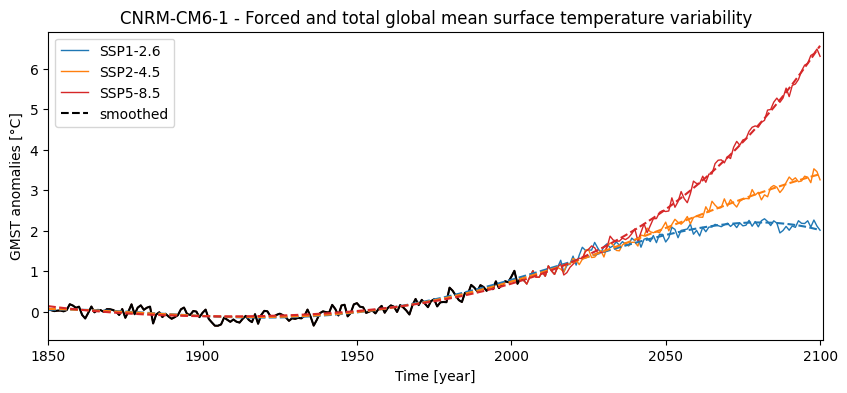

In [9]:
# Compute polynomial fit
deg          = 4

coefs_ssp126 = np.polyfit(ssp126['ts']['year'], ssp126['tsa'].sel({'model': model}), deg)
coefs_ssp245 = np.polyfit(ssp245['ts']['year'], ssp245['tsa'].sel({'model': model}), deg)
coefs_ssp585 = np.polyfit(ssp585['ts']['year'], ssp585['tsa'].sel({'model': model}), deg)

frcd_ssp126  = np.polyval(coefs_ssp126, ssp126['ts']['year'])
frcd_ssp245  = np.polyval(coefs_ssp245, ssp245['ts']['year'])
frcd_ssp585  = np.polyval(coefs_ssp585, ssp585['ts']['year'])

# create figure and axe 
fig, ax = plt.subplots(1,1, figsize=(10, 4))

# plot model time-series
ax.plot( ssp126['ts']['year'], ssp126['tsa'].sel({'model': model}), label='SSP1-2.6', lw=1., c='tab:blue')
ax.plot( ssp245['ts']['year'], ssp245['tsa'].sel({'model': model}), label='SSP2-4.5', lw=1., c='tab:orange')
ax.plot( ssp585['ts']['year'], ssp585['tsa'].sel({'model': model}), label='SSP5-8.5', lw=1., c='tab:red')
ax.plot( ssp126['ts']['year'][:155], ssp126['tsa'].sel({'model': model})[:155],              c='k')

# plot model smoothed time-series
ax.plot( ssp126['ts']['year'], frcd_ssp126, lw=1.5, ls='--', c='tab:blue')
ax.plot( ssp245['ts']['year'], frcd_ssp245, lw=1.5, ls='--', c='tab:orange')
ax.plot( ssp585['ts']['year'], frcd_ssp585, lw=1.5, ls='--', c='tab:red')
ax.plot( [0, 1], [1, 1], label='smoothed',  lw=1.5, ls='--', c='k')

# ax properties
ax.set_xlabel('Time [year]')
ax.set_ylabel(r'GMST anomalies [°C]')

ax.set_xlim((1850, 2101))

ax.legend(loc=2)

_ = ax.set_title("{} - Forced and total global mean surface temperature variability".format(model))

<font color="blue">

- a fourth order polynomial fit provides the best results, and it is the choice done in [Hawkins and Sutton (2009)](https://doi.org/10.1007/s00382-010-0810-6).
        
</font>

#### Question 6

* _Using the `welch` function ([scipy.signal](https://docs.scipy.org/doc/scipy/reference/generated/scipy.signal.welch.html)) plot the power spectral density for global mean surface temperature time-series as well as the forced and internal variability._
* _How do you interpret the results ? Is your filtering method seems correct ? If you would be able to run a climate model, propose a method to better estimate the internal variability._ 


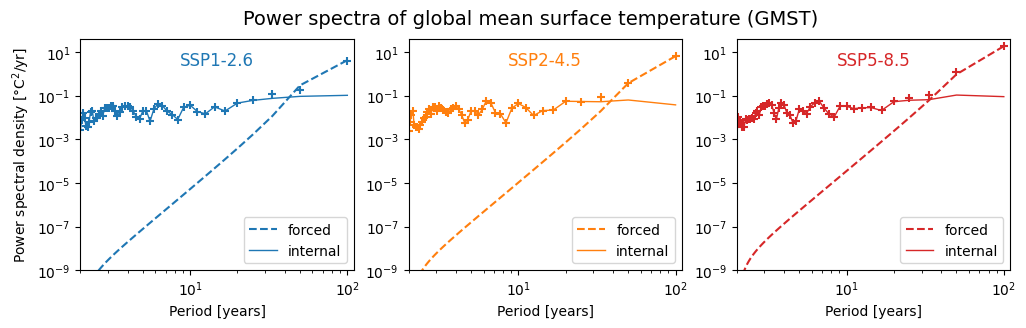

In [10]:
fig, axes = plt.subplots(1,3, figsize=(12, 3))


# power spectra for the full signal (anomalies of GMST) 
f126, p126 = scipy.signal.welch(ssp126['tsa'].sel({'model': model}), fs=1, scaling='density', nperseg=100)
f245, p245 = scipy.signal.welch(ssp245['tsa'].sel({'model': model}), fs=1, scaling='density', nperseg=100)
f585, p585 = scipy.signal.welch(ssp585['tsa'].sel({'model': model}), fs=1, scaling='density', nperseg=100)

axes[0].scatter(1/f126[1:],   p126[1:], s=30, marker='+', c='tab:blue' )
axes[1].scatter(1/f245[1:],   p245[1:], s=30, marker='+', c='tab:orange' )
axes[2].scatter(1/f585[1:],   p585[1:], s=30, marker='+', c='tab:red' )


# power spectra for the forced variability only
f126, p126 = scipy.signal.welch(frcd_ssp126, fs=1, scaling='density', nperseg=100)
f245, p245 = scipy.signal.welch(frcd_ssp245, fs=1, scaling='density', nperseg=100)
f585, p585 = scipy.signal.welch(frcd_ssp585, fs=1, scaling='density', nperseg=100)

axes[0].plot(1/f126[1:],   p126[1:], label='forced', ls='--', lw=1.5, c='tab:blue' )
axes[1].plot(1/f245[1:],   p245[1:], label='forced', ls='--', lw=1.5, c='tab:orange' )
axes[2].plot(1/f585[1:],   p585[1:], label='forced', ls='--', lw=1.5, c='tab:red' )


# power spectra for the internal variability only
f126, p126 = scipy.signal.welch(ssp126['tsa'].sel({'model': model}) - frcd_ssp126, fs=1, scaling='density', 
                                nperseg=100)
f245, p245 = scipy.signal.welch(ssp245['tsa'].sel({'model': model}) - frcd_ssp245, fs=1, scaling='density', 
                                nperseg=100)
f585, p585 = scipy.signal.welch(ssp585['tsa'].sel({'model': model}) - frcd_ssp585, fs=1, scaling='density', 
                                nperseg=100)

axes[0].plot(1/f126[1:],   p126[1:], label='internal', ls='-', lw=1., c='tab:blue' )
axes[1].plot(1/f245[1:],   p245[1:], label='internal', ls='-', lw=1., c='tab:orange' )
axes[2].plot(1/f585[1:],   p585[1:], label='internal', ls='-', lw=1., c='tab:red' )


# ax parameters
axes[0].set_title('SSP1-2.6', y=0.85, c='tab:blue' )
axes[1].set_title('SSP2-4.5', y=0.85, c='tab:orange' )
axes[2].set_title('SSP5-8.5', y=0.85, c='tab:red' )

for i, ax in enumerate(axes):
    ax.set_xscale('log')
    ax.set_yscale('log')

    ax.set_xlim((2, 110))
    ax.set_xlabel(r'Period [years]')
    
    ax.set_ylim((1e-9, 40))
    if i == 0:
        ax.set_ylabel(r'Power spectral density [°C$^2$/yr]')

    ax.legend(loc=4)

_ = fig.suptitle('Power spectra of global mean surface temperature (GMST)', fontsize=14)

<font color="blue">

power spectra allow to compare signals by decomposing into a sum of finite simple signals (using Fourier transform). The energy or the density of each signal is estimated and plotted against its frequency. 
    
The figure highlights how our method has filtered the GMST anomaly time-series. The polynomial fit (i.e. the forced signal in dashed line) clearly keep the shortest frequencies (>30 years) while higher frequencies are absent (not the log scale). In contrast, the residuals (i.e. the internal variability in solid line) conserve the signal at high frequencies but reduce the spectral density for longer periods. To a first order, the method can extract the internal variability from the original time-series. 
    
Few remarks :
  - we can aleready note that the internal variability is similar between scenario; this supports the definition of a constant internal variability $V$
  - internal variability at low frequencies does not vanished due to some decadal / centenial variability (different from one model to another)
  - the forced signal is stronger for higher radiative forcing scenario (SSP5 vs. SSP1)

</font>

#### Question 7

* _Compute the forced and internal variability for each model._
* _Propose figures that check the differences between models. How can you explain the differences ?_

In [11]:
# init empty arrays
forced_ssp126 = np.zeros_like(ssp126['tsa'])
forced_ssp245 = np.zeros_like(ssp245['tsa'])
forced_ssp585 = np.zeros_like(ssp585['tsa'])

internal_ssp126 = forced_ssp126.copy()
internal_ssp245 = forced_ssp126.copy()
internal_ssp585 = forced_ssp126.copy()

# Compute fourth-order polynomial fit
deg           = 4
    
for im, model in enumerate(ssp126['ts']['model']):
    coefs_ssp126 = np.polyfit(ssp126['ts']['year'], ssp126['tsa'].sel({'model': model}), deg)
    coefs_ssp245 = np.polyfit(ssp245['ts']['year'], ssp245['tsa'].sel({'model': model}), deg)
    coefs_ssp585 = np.polyfit(ssp585['ts']['year'], ssp585['tsa'].sel({'model': model}), deg)

    forced_ssp126[:,im]  = np.polyval(coefs_ssp126, ssp126['ts']['year'])
    forced_ssp245[:,im]  = np.polyval(coefs_ssp245, ssp245['ts']['year'])
    forced_ssp585[:,im]  = np.polyval(coefs_ssp585, ssp585['ts']['year'])
    
# compute internal variability
internal_ssp126 = ssp126['tsa'] - forced_ssp126
internal_ssp245 = ssp245['tsa'] - forced_ssp245
internal_ssp585 = ssp585['tsa'] - forced_ssp585

# save in python dictionaries
ssp126['tsa_forced'] = xr.DataArray(data=forced_ssp126, dims=('year', 'model'), coords=ssp126['ts'].coords)
ssp245['tsa_forced'] = xr.DataArray(data=forced_ssp245, dims=('year', 'model'), coords=ssp245['ts'].coords)
ssp585['tsa_forced'] = xr.DataArray(data=forced_ssp585, dims=('year', 'model'), coords=ssp585['ts'].coords)

ssp126['tsa_internal'] = xr.DataArray(data=internal_ssp126, dims=('year', 'model'), coords=ssp126['ts'].coords)
ssp245['tsa_internal'] = xr.DataArray(data=internal_ssp245, dims=('year', 'model'), coords=ssp245['ts'].coords)
ssp585['tsa_internal'] = xr.DataArray(data=internal_ssp585, dims=('year', 'model'), coords=ssp585['ts'].coords)

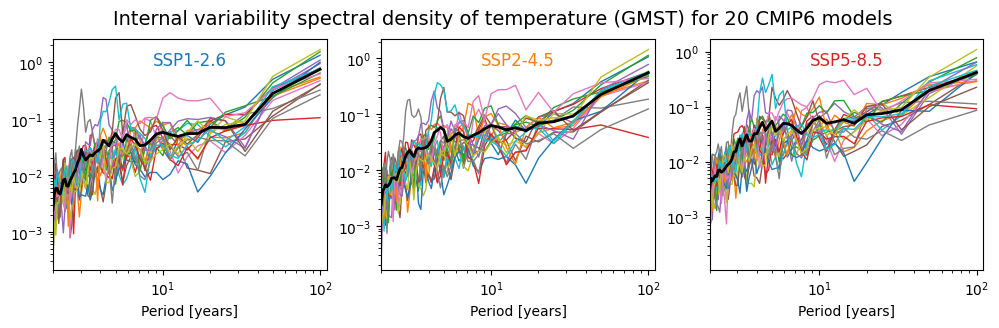

In [12]:
# plot
fig, axes = plt.subplots(1,3, figsize=(12, 3))

# SSP1 power spectra
f, pw = scipy.signal.welch(ssp126['tsa_internal'], fs=1, axis=0, scaling='density', 
                           nperseg=100)
axes[0].plot(1/f[1:],   pw[1:],              lw=1.)
axes[0].plot(1/f[1:],   pw[1:].mean(axis=1), lw=2., c='k')


# SSP2 power spectra
f, pw = scipy.signal.welch(ssp245['tsa_internal'], fs=1, axis=0, scaling='density', 
                           nperseg=100)
axes[1].plot(1/f[1:],   pw[1:],              lw=1.)
axes[1].plot(1/f[1:],   pw[1:].mean(axis=1), lw=2., c='k')


# SSP1 power spectra
f, pw = scipy.signal.welch(ssp585['tsa_internal'], fs=1, axis=0, scaling='density', 
                           nperseg=100)
axes[2].plot(1/f[1:],   pw[1:],              lw=1.)
axes[2].plot(1/f[1:],   pw[1:].mean(axis=1), lw=2., c='k')


# axes properties
axes[0].set_title('SSP1-2.6', y=0.85, c='tab:blue' )
axes[1].set_title('SSP2-4.5', y=0.85, c='tab:orange' )
axes[2].set_title('SSP5-8.5', y=0.85, c='tab:red' )

for ax in axes:
    ax.set_xscale('log')
    ax.set_yscale('log')

    ax.set_xlim((2, 110))
    ax.set_xlabel(r'Period [years]')
    
    if i == 0:
        ax.set_ylabel(r'Power spectral density [°C$^2$/yr]')
    
_ = fig.suptitle("Internal variability spectral density of temperature (GMST) for 20 CMIP6 models", fontsize=14)

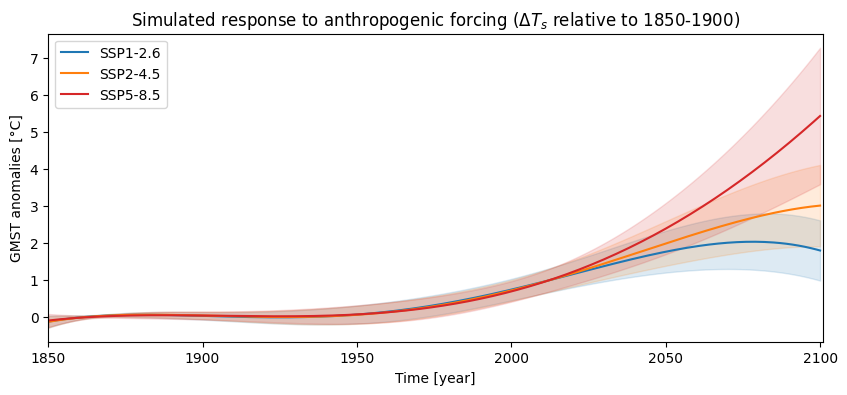

In [13]:
# plot
fig, ax = plt.subplots(1,1, figsize=(10, 4))

# get mean and std for each scenario
mean126_frcd = ssp126['tsa_forced'].mean('model')
std126_frcd  = ssp126['tsa_forced'].std('model')

mean245_frcd = ssp245['tsa_forced'].mean('model')
std245_frcd  = ssp245['tsa_forced'].std('model')

mean585_frcd = ssp585['tsa_forced'].mean('model')
std585_frcd  = ssp585['tsa_forced'].std('model')

# plot multi-model mean
ax.plot( ssp126['ts']['year'], mean126_frcd,         label='SSP1-2.6', lw=1.5, c='tab:blue')
ax.plot( ssp245['ts']['year'], mean245_frcd,         label='SSP2-4.5', lw=1.5, c='tab:orange')
ax.plot( ssp585['ts']['year'], mean585_frcd,         label='SSP5-8.5', lw=1.5, c='tab:red')

# plot range
years = ssp126['ts']['year']
ax.fill_between( years, mean126_frcd+1.64*std126_frcd, mean126_frcd-1.64*std126_frcd, 
                                                                color='tab:blue',   alpha=0.15)
ax.fill_between( years, mean245_frcd+1.64*std245_frcd, mean245_frcd-1.64*std245_frcd, 
                                                                color='tab:orange', alpha=0.15)
ax.fill_between( years, mean585_frcd+1.64*std585_frcd, mean585_frcd-1.64*std585_frcd, 
                                                                color='tab:red',    alpha=0.15)

# axe properties
ax.set_xlabel('Time [year]')
ax.set_ylabel(r'GMST anomalies [°C]')

ax.set_xlim((1850, 2101))

ax.legend(loc=2)

_ = ax.set_title(r"Simulated response to anthropogenic forcing ($\Delta T_s$ relative to 1850-1900)")

<font color="blue">
   
Discuss here differences in 1) internal variability and 2) forced response.
    
For 1) we can note differences in power signal at all frequencies; even the centenial variability is very different across models
    
For 2) even if all models are based on physical equations (transport and conservation equations), they use different numerical choices (how to solve the equation) and different modelling choices (how to represent processes). In particular, climate models cannot fully resolve small-scale processes, such as those related to clouds – which are thought to be important for climate sensitivity.
    
  - **Are these differences are problematic ?**\
    Not necessary. We can remark that they give similar trends (global surface temperature increase, as well as upward longwave radiation). This is rather reassuring in the sense that we can trust their results in broad terms. CMIP results feed the IPCC Assessment Reports in which confidence levels on climate metrics are given from that model results match or not.
    

  - **Which model is the best ?**\
    Probably none. Models are often run on historical period (1950-today) and compared to observations. However, the answer will be different depending on the metric considered to evaluate the model. Indeed, no model performs well everywhere. Regarding future climate projection, it is often admit that the multi model mean gives the best estimate while the standard deviation gives the uncertainty.


</font>

#### Question 8

* _Use the definition of the three uncertainty sources to compute $V$, $M$ and $S$ for the global mean surface temperature._
* _Normalize each source with the total uncertainty to create a figure similar to the one in introduction ([Fig. 2](#tp4-fig2)). Interpret and comment your results._

In [14]:
# Compute uncertainty sources

# 1. Internal variability (V)
internal_var = xr.concat( (ssp126['tsa_internal'], ssp245['tsa_internal'], ssp585['tsa_internal']), dim='year')

iv_variance = internal_var.var(axis=0)    # variance across the scenarios and the years
iv_mea      = iv_variance.mean().data     # multi-model mean
V           = np.ones_like(years)*iv_mea

# 2. Model uncertainty (M)
M_ssp126 = ssp126['tsa_forced'].var(axis=1)
M_ssp245 = ssp245['tsa_forced'].var(axis=1)
M_ssp585 = ssp585['tsa_forced'].var(axis=1)

M = 1/3 * (M_ssp126 + M_ssp245 + M_ssp585).data # multi-scenario mean

# 3. Scenario uncertainty
forced_avg =  xr.concat( (mean126_frcd, mean245_frcd, mean585_frcd), dim='scenario')

S = forced_avg.var(dim='scenario').data    # variance across the scenarios

# Total uncertainty
total_unc = V + M + S

/home/torres/envs/eddy-hist/lib/python3.9/site-packages/xarray/core/concat.py:532: FutureWarning: unique with argument that is not not a Series, Index, ExtensionArray, or np.ndarray is deprecated and will raise in a future version.
  common_dims = tuple(pd.unique([d for v in vars for d in v.dims]))
/home/torres/envs/eddy-hist/lib/python3.9/site-packages/xarray/core/concat.py:532: FutureWarning: unique with argument that is not not a Series, Index, ExtensionArray, or np.ndarray is deprecated and will raise in a future version.
  common_dims = tuple(pd.unique([d for v in vars for d in v.dims]))


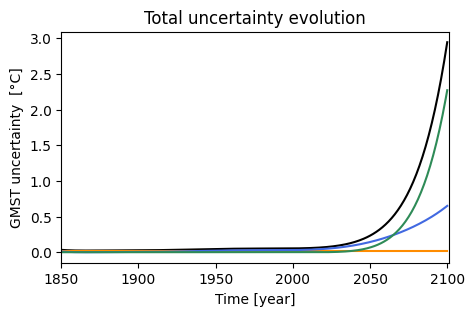

In [15]:
# First, check that total uncertainty T increases with time
fig, ax = plt.subplots(1,1, figsize=(5, 3))

# plot multi-model mean
ax.plot( years, total_unc,  c='k')
ax.plot( years, V,          c='darkorange')
ax.plot( years, M,          c='royalblue')
ax.plot( years, S,          c='seagreen')

ax.set_xlabel('Time [year]')
ax.set_ylabel(r'GMST uncertainty  [°C]')

ax.set_xlim((1850, 2101))

_ = ax.set_title(r"Total uncertainty evolution")

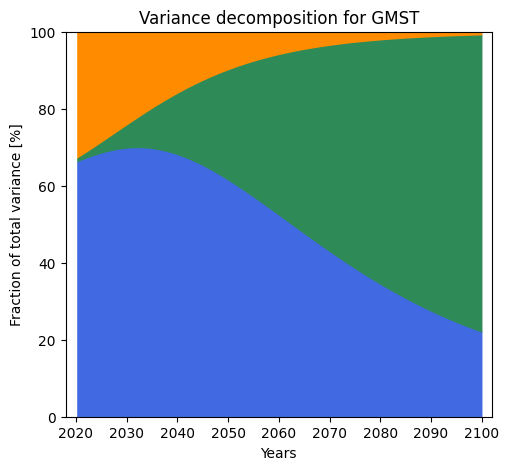

In [16]:
# Plot uncertainty decomposition
fig, ax = plt.subplots(1,1, figsize=(5.5, 5))

# plot fraction
ax.fill_between( years, 100*M/total_unc, np.zeros_like(M),                  color='royalblue')
ax.fill_between( years, 100*(M + S)/total_unc,      100*M/total_unc,        color='seagreen')
ax.fill_between( years, 100*(M + S + V)/total_unc , 100*(M + S)/total_unc,  color='darkorange')

#
ax.set_ylim((0,100))
ax.set_xlim((2018, 2102))
ax.fill_between( [2018, 2020], [100, 100], [0, 0],  color='white')
ax.set_ylabel('Fraction of total variance [%]')
ax.set_xlabel('Years')

_ = ax.set_title(r"Variance decomposition for GMST")

<font color="blue">

- **At short/mid term** (< 2040) the scenario makes little difference and most of the uncertainty is due to the models.:

  -  _modelling choices_ (parameters) cause difference between models
 
  -  the simulated climate still have an _internal variability_. Indeed, climate variables exhibit natural fluctuations meaning that two simulations starting from a different state (but with the same climate in a statistical sense) will give different results. This leads to uncertainties that climate scientists try to quantify. In practive, several simulations of the same individual model are runs with different initialisation (intial state). *Tens* of simulations of *tens* model for *different* scenario $\rightarrow$ this is really really costly and a non-negligeable source of greenhouse gases emissions..

- **At long term** (>2050) the choosen scenario matters a lot !! 

</font>

<a id="section-3"></a>
## 3. Application to other variables and finer regions

We will now apply the same decomposition to evaluate uncertainties for other climate projections.

#### Question 9

* _Compute and plot the three uncertainty sources (normalized) for the global mean precipitation._
* _How do you explain the differences and similarities with the GMST analysis ?_

In [17]:
## Decompose forced and internal variability

# init empty arrays
forced_ssp126 = np.zeros_like(ssp126['pra'])
forced_ssp245 = np.zeros_like(ssp245['pra'])
forced_ssp585 = np.zeros_like(ssp585['pra'])

internal_ssp126 = forced_ssp126.copy()
internal_ssp245 = forced_ssp126.copy()
internal_ssp585 = forced_ssp126.copy()

# compute fourth-order polynomial fit
deg           = 4
    
for im, model in enumerate(ssp126['pr']['model']):
    coefs_ssp126 = np.polyfit(ssp126['pr']['year'], ssp126['pra'].sel({'model': model}), deg)
    coefs_ssp245 = np.polyfit(ssp245['pr']['year'], ssp245['pra'].sel({'model': model}), deg)
    coefs_ssp585 = np.polyfit(ssp585['pr']['year'], ssp585['pra'].sel({'model': model}), deg)

    forced_ssp126[:,im]  = np.polyval(coefs_ssp126, ssp126['pr']['year'])
    forced_ssp245[:,im]  = np.polyval(coefs_ssp245, ssp245['pr']['year'])
    forced_ssp585[:,im]  = np.polyval(coefs_ssp585, ssp585['pr']['year'])
    
# compute internal variability
internal_ssp126 = ssp126['pra'] - forced_ssp126
internal_ssp245 = ssp245['pra'] - forced_ssp245
internal_ssp585 = ssp585['pra'] - forced_ssp585

# save in python dictionaries
ssp126['pra_forced'] = xr.DataArray(data=forced_ssp126, dims=('year', 'model'), coords=ssp126['pr'].coords)
ssp245['pra_forced'] = xr.DataArray(data=forced_ssp245, dims=('year', 'model'), coords=ssp245['pr'].coords)
ssp585['pra_forced'] = xr.DataArray(data=forced_ssp585, dims=('year', 'model'), coords=ssp585['pr'].coords)

ssp126['pra_internal'] = xr.DataArray(data=internal_ssp126, dims=('year', 'model'), coords=ssp126['pr'].coords)
ssp245['pra_internal'] = xr.DataArray(data=internal_ssp245, dims=('year', 'model'), coords=ssp245['pr'].coords)
ssp585['pra_internal'] = xr.DataArray(data=internal_ssp585, dims=('year', 'model'), coords=ssp585['pr'].coords)


## Compute uncertainty sources

# 1. Internal variability (V)
internal_var = xr.concat( (ssp126['pra_internal'], ssp245['pra_internal'], ssp585['pra_internal']), dim='year')

iv_variance = internal_var.var(axis=0)    # variance across the scenarios and the years
iv_mea      = iv_variance.mean().data     # multi-model mean
V_pr        = np.ones_like(ssp126['pr']['year'])*iv_mea

# 2. Model uncertainty (M)
M_ssp126 = ssp126['pra_forced'].var(axis=1)
M_ssp245 = ssp245['pra_forced'].var(axis=1)
M_ssp585 = ssp585['pra_forced'].var(axis=1)

M_pr = 1/3 * (M_ssp126 + M_ssp245 + M_ssp585).data # multi-scenario mean

# 3. Scenario uncertainty
mean126_frcd = ssp126['pra_forced'].mean('model')
mean245_frcd = ssp245['pra_forced'].mean('model')
mean585_frcd = ssp585['pra_forced'].mean('model')

forced_avg =  xr.concat( (mean126_frcd, mean245_frcd, mean585_frcd), dim='scenario')

S_pr = forced_avg.var(dim='scenario').data    # variance across the scenarios

# Total uncertainty
total_pr = V_pr + M_pr + S_pr

/home/torres/envs/eddy-hist/lib/python3.9/site-packages/xarray/core/concat.py:532: FutureWarning: unique with argument that is not not a Series, Index, ExtensionArray, or np.ndarray is deprecated and will raise in a future version.
  common_dims = tuple(pd.unique([d for v in vars for d in v.dims]))
/home/torres/envs/eddy-hist/lib/python3.9/site-packages/xarray/core/concat.py:532: FutureWarning: unique with argument that is not not a Series, Index, ExtensionArray, or np.ndarray is deprecated and will raise in a future version.
  common_dims = tuple(pd.unique([d for v in vars for d in v.dims]))


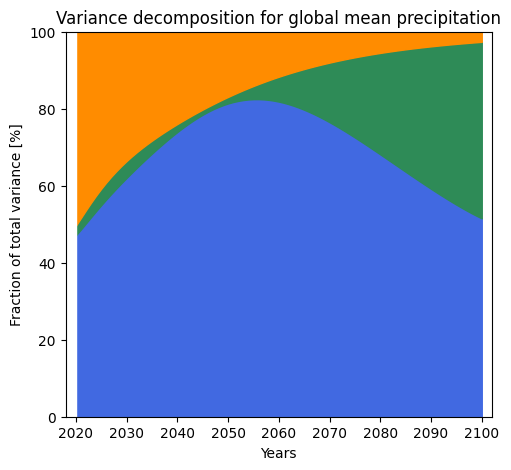

In [18]:
# Plot uncertainty decomposition
fig, ax = plt.subplots(1,1, figsize=(5.5, 5))

# plot fraction
ax.fill_between( ssp126['pr']['year'], 100*M_pr/total_pr, np.zeros_like(M_pr),                  color='royalblue')
ax.fill_between( ssp126['pr']['year'], 100*(M_pr + S_pr)/total_pr,    100*M_pr/total_pr,        color='seagreen')
ax.fill_between( ssp126['pr']['year'], 100*(M_pr+S_pr+V_pr)/total_pr, 100*(M_pr+S_pr)/total_pr, color='darkorange')

#
ax.set_ylim((0,100))
ax.set_xlim((2018, 2102))
ax.fill_between( [2018, 2020], [100, 100], [0, 0],  color='white')
ax.set_ylabel('Fraction of total variance [%]')
ax.set_xlabel('Years')

_ = ax.set_title(r"Variance decomposition for global mean precipitation")

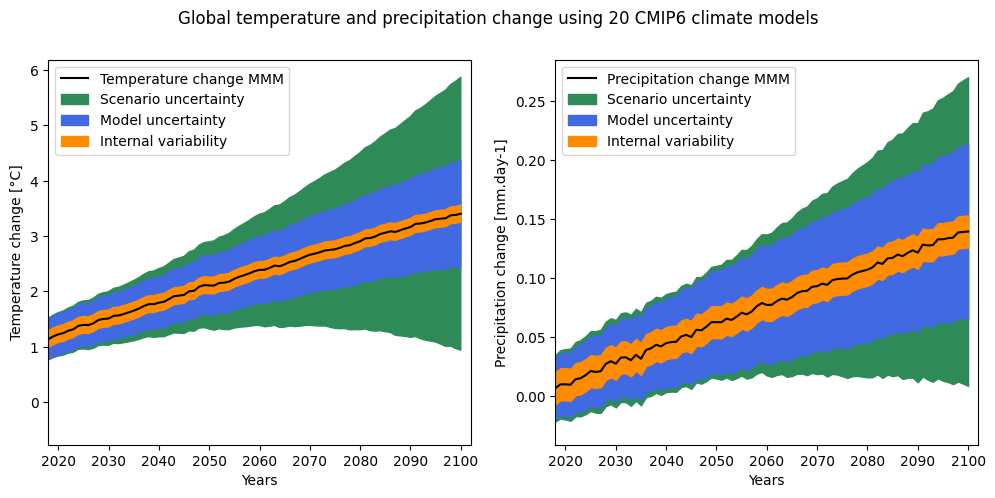

In [19]:
# Plot uncertainty decomposition
fig, axes = plt.subplots(1,2, figsize=(12, 5))

# plot evolution with uncertainty intervals

# ts
mmm_tsa_ssp126 = 1/3 * (ssp126['tsa'] + ssp245['tsa'] + ssp585['tsa']).mean('model')
err_mod        = M**0.5 + V**0.5
err_sce        = M**0.5 + V**0.5 + S**0.5

axes[0].plot(         ssp126['tsa']['year'], mmm_tsa_ssp126,                                 
                                                        label='Temperature change MMM', color='k')
axes[0].fill_between( ssp126['tsa']['year'], mmm_tsa_ssp126+err_sce, mmm_tsa_ssp126-err_sce, 
                                                        label='Scenario uncertainty',   color='seagreen')
axes[0].fill_between( ssp126['tsa']['year'], mmm_tsa_ssp126+err_mod, mmm_tsa_ssp126-err_mod, 
                                                         label='Model uncertainty',     color='royalblue')
axes[0].fill_between( ssp126['tsa']['year'], mmm_tsa_ssp126+V**0.5,  mmm_tsa_ssp126-V**0.5,  
                                                         label='Internal variability',  color='darkorange')

# pr
mmm_pra_ssp126 = 1/3 * (ssp126['pra'] + ssp245['pra'] + ssp585['pra']).mean('model')
err_var        = V_pr**0.5
err_mod        = M_pr**0.5 + V_pr**0.5
err_sce        = M_pr**0.5 + V_pr**0.5 + S_pr**0.5

axes[1].plot(         ssp126['pra']['year'], mmm_pra_ssp126,                                 
                                                        label='Precipitation change MMM', color='k')
axes[1].fill_between( ssp126['pra']['year'], mmm_pra_ssp126+err_sce, mmm_pra_ssp126-err_sce, 
                                                        label='Scenario uncertainty',   color='seagreen')
axes[1].fill_between( ssp126['pra']['year'], mmm_pra_ssp126+err_mod, mmm_pra_ssp126-err_mod, 
                                                         label='Model uncertainty',     color='royalblue')
axes[1].fill_between( ssp126['pra']['year'], mmm_pra_ssp126+err_var, mmm_pra_ssp126-err_var,  
                                                         label='Internal variability',  color='darkorange')


# axes properties
axes[0].set_ylabel('Temperature change [°C]')
axes[1].set_ylabel('Precipitation change [mm.day-1]')

for ax in axes:
    ax.set_xlim((2018, 2102))
    ax.set_xlabel('Years')    
    ax.legend(loc=2)

_ = fig.suptitle(r"Global temperature and precipitation change using 20 CMIP6 climate models")

<font color="blue">

There are some similarities with the global mean temperature but scenario uncertainty as less important; the model uncertainty dominates at almost all time-scales (except at the end of simulations where M/S ~ 1). Internal variability seems also more important 

</font>

#### Question 10

We will now focus on the regional and seasonal effect using winter and summer temperature projections in France. 

* _Redo the analysis for the summer temperature in France._
* _What are the differences with the uncertainties associated to the global temperature change ? How can you explain these differences ?_


__Help:__ the following python code, load seasonal and regional temperature in France and add it to the python dictionaries for each SSPs.   

```python

# load 20 models in csv (.asc) files using pandas and convert into xarray.Dataset
df = pd.read_csv('../data/'+"T_fr_DJF_ssp126.asc", sep=" ")-273.15
ssp126['ts_fr_w'] = xr.DataArray(data=df.values,
                            dims=('year', 'model'),
                            coords={'year': np.array(df.index), 'model': np.array(df.columns)}
                           )

df = pd.read_csv('../data/'+"T_fr_DJF_ssp245.asc", sep=" ")-273.15
ssp245['ts_fr_w'] = xr.DataArray(data=df.values,
                            dims=('year', 'model'),
                            coords={'year': np.array(df.index), 'model': np.array(df.columns)}
                           )

df = pd.read_csv('../data/'+"T_fr_DJF_ssp585.asc", sep=" ")-273.15
ssp585['ts_fr_w'] = xr.DataArray(data=df.values,
                            dims=('year', 'model'),
                            coords={'year': np.array(df.index), 'model': np.array(df.columns)}
                           )

# load some model outputs with precip in csv (.asc)
df = pd.read_csv('../data/'+"T_fr_JJA_ssp126.asc", sep=" ", index_col=0)
ssp126['ts_fr_s'] = xr.DataArray(data=df.values,
                            dims=('year', 'model'),
                            coords={'year': np.array(df.index), 'model': np.array(df.columns)}
                           )

df = pd.read_csv('../data/'+"T_fr_JJA_ssp245.asc", sep=" ", index_col=0)
ssp245['ts_fr_s'] = xr.DataArray(data=df.values,
                            dims=('year', 'model'),
                            coords={'year': np.array(df.index), 'model': np.array(df.columns)}
                           )

df = pd.read_csv('../data/'+"T_fr_JJA_ssp585.asc", sep=" ", index_col=0)
ssp585['ts_fr_s'] = xr.DataArray(data=df.values,
                            dims=('year', 'model'),
                            coords={'year': np.array(df.index), 'model': np.array(df.columns)}
                           )

```

In [20]:
# load 20 models in csv (.asc) files using pandas and convert into xarray.Dataset
df = pd.read_csv('../data/'+"T_fr_DJF_ssp126.asc", sep=" ")-273.15
ssp126['ts_fr_w'] = xr.DataArray(data=df.values,
                            dims=('year', 'model'),
                            coords={'year': np.array(df.index), 'model': np.array(df.columns)}
                           )

df = pd.read_csv('../data/'+"T_fr_DJF_ssp245.asc", sep=" ")-273.15
ssp245['ts_fr_w'] = xr.DataArray(data=df.values,
                            dims=('year', 'model'),
                            coords={'year': np.array(df.index), 'model': np.array(df.columns)}
                           )

df = pd.read_csv('../data/'+"T_fr_DJF_ssp585.asc", sep=" ")-273.15
ssp585['ts_fr_w'] = xr.DataArray(data=df.values,
                            dims=('year', 'model'),
                            coords={'year': np.array(df.index), 'model': np.array(df.columns)}
                           )

# load some model outputs with precip in csv (.asc)
df = pd.read_csv('../data/'+"T_fr_JJA_ssp126.asc", sep=" ")-273.15
ssp126['ts_fr_s'] = xr.DataArray(data=df.values,
                            dims=('year', 'model'),
                            coords={'year': np.array(df.index), 'model': np.array(df.columns)}
                           )

df = pd.read_csv('../data/'+"T_fr_JJA_ssp245.asc", sep=" ")-273.15
ssp245['ts_fr_s'] = xr.DataArray(data=df.values,
                            dims=('year', 'model'),
                            coords={'year': np.array(df.index), 'model': np.array(df.columns)}
                           )

df = pd.read_csv('../data/'+"T_fr_JJA_ssp585.asc", sep=" ")-273.15
ssp585['ts_fr_s'] = xr.DataArray(data=df.values,
                            dims=('year', 'model'),
                            coords={'year': np.array(df.index), 'model': np.array(df.columns)}
                           )


In [21]:
## Compute anomalies
ssp126['tsa_fr_s'] = (ssp126['ts_fr_s'] - ssp126['ts_fr_s'].isel({'year': slice(0, 50)}).mean('year'))
ssp245['tsa_fr_s'] = (ssp245['ts_fr_s'] - ssp245['ts_fr_s'].isel({'year': slice(0, 50)}).mean('year'))
ssp585['tsa_fr_s'] = (ssp585['ts_fr_s'] - ssp585['ts_fr_s'].isel({'year': slice(0, 50)}).mean('year'))

## Decompose forced and internal variability

# init empty arrays
forced_ssp126 = np.zeros_like(ssp126['tsa_fr_s'])
forced_ssp245 = np.zeros_like(ssp245['tsa_fr_s'])
forced_ssp585 = np.zeros_like(ssp585['tsa_fr_s'])

internal_ssp126 = forced_ssp126.copy()
internal_ssp245 = forced_ssp126.copy()
internal_ssp585 = forced_ssp126.copy()

# compute fourth-order polynomial fit
deg           = 4
    
for im, model in enumerate(ssp126['ts_fr_s']['model']):
    coefs_ssp126 = np.polyfit(ssp126['ts']['year'], ssp126['tsa_fr_s'].sel({'model': model}), deg)
    coefs_ssp245 = np.polyfit(ssp245['ts']['year'], ssp245['tsa_fr_s'].sel({'model': model}), deg)
    coefs_ssp585 = np.polyfit(ssp585['ts']['year'], ssp585['tsa_fr_s'].sel({'model': model}), deg)

    forced_ssp126[:,im]  = np.polyval(coefs_ssp126, ssp126['ts']['year'])
    forced_ssp245[:,im]  = np.polyval(coefs_ssp245, ssp245['ts']['year'])
    forced_ssp585[:,im]  = np.polyval(coefs_ssp585, ssp585['ts']['year'])
    
# compute internal variability
internal_ssp126 = ssp126['tsa_fr_s'] - forced_ssp126
internal_ssp245 = ssp245['tsa_fr_s'] - forced_ssp245
internal_ssp585 = ssp585['tsa_fr_s'] - forced_ssp585

# save in python dictionaries
ssp126['tsa_fr_forced'] = xr.DataArray(data=forced_ssp126, dims=('year', 'model'), coords=ssp126['ts'].coords)
ssp245['tsa_fr_forced'] = xr.DataArray(data=forced_ssp245, dims=('year', 'model'), coords=ssp245['ts'].coords)
ssp585['tsa_fr_forced'] = xr.DataArray(data=forced_ssp585, dims=('year', 'model'), coords=ssp585['ts'].coords)

ssp126['tsa_fr_internal'] = xr.DataArray(data=internal_ssp126, dims=('year', 'model'), coords=ssp126['ts'].coords)
ssp245['tsa_fr_internal'] = xr.DataArray(data=internal_ssp245, dims=('year', 'model'), coords=ssp245['ts'].coords)
ssp585['tsa_fr_internal'] = xr.DataArray(data=internal_ssp585, dims=('year', 'model'), coords=ssp585['ts'].coords)


## Compute uncertainty sources

# 1. Internal variability (V)
arrays       = (ssp126['tsa_fr_internal'], ssp245['tsa_fr_internal'], ssp585['tsa_fr_internal'])
internal_var = xr.concat( arrays, dim='year')

iv_variance = internal_var.var(axis=0)    # variance across the scenarios and the years
iv_mea      = iv_variance.mean().data     # multi-model mean
V_fr_s      = np.ones_like(ssp126['tsa_fr_s']['year'])*iv_mea

# 2. Model uncertainty (M)
M_ssp126 = ssp126['tsa_fr_forced'].var(axis=1)
M_ssp245 = ssp245['tsa_fr_forced'].var(axis=1)
M_ssp585 = ssp585['tsa_fr_forced'].var(axis=1)

M_fr_s = 1/3 * (M_ssp126 + M_ssp245 + M_ssp585).data # multi-scenario mean

# 3. Scenario uncertainty
mean126_frcd = ssp126['tsa_fr_forced'].mean('model')
mean245_frcd = ssp245['tsa_fr_forced'].mean('model')
mean585_frcd = ssp585['tsa_fr_forced'].mean('model')

forced_avg =  xr.concat( (mean126_frcd, mean245_frcd, mean585_frcd), dim='scenario')

S_fr_s = forced_avg.var(dim='scenario').data    # variance across the scenarios

# Total uncertainty
T_fr_s = V_fr_s + M_fr_s + S_fr_s

/home/torres/envs/eddy-hist/lib/python3.9/site-packages/xarray/core/concat.py:532: FutureWarning: unique with argument that is not not a Series, Index, ExtensionArray, or np.ndarray is deprecated and will raise in a future version.
  common_dims = tuple(pd.unique([d for v in vars for d in v.dims]))
/home/torres/envs/eddy-hist/lib/python3.9/site-packages/xarray/core/concat.py:532: FutureWarning: unique with argument that is not not a Series, Index, ExtensionArray, or np.ndarray is deprecated and will raise in a future version.
  common_dims = tuple(pd.unique([d for v in vars for d in v.dims]))


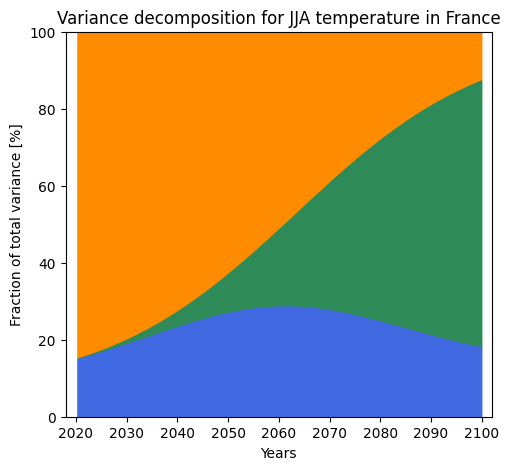

In [22]:
# Plot uncertainty decomposition
fig, ax = plt.subplots(1,1, figsize=(5.5, 5))

# plot fraction
U_mod = 100*M_fr_s/T_fr_s
U_sce = 100*(M_fr_s + S_fr_s)/T_fr_s
U_var = 100*(M_fr_s + S_fr_s + V_fr_s)/T_fr_s

ax.fill_between( ssp126['ts_fr_s']['year'], U_mod, np.zeros_like(M_fr_s), color='royalblue')
ax.fill_between( ssp126['ts_fr_s']['year'], U_sce, U_mod,                 color='seagreen')
ax.fill_between( ssp126['ts_fr_s']['year'], U_var, U_sce,                 color='darkorange')

#
ax.set_ylim((0,100))
ax.set_xlim((2018, 2102))
ax.fill_between( [2018, 2020], [100, 100], [0, 0],  color='white')
ax.set_ylabel('Fraction of total variance [%]')
ax.set_xlabel('Years')

_ = ax.set_title(r"Variance decomposition for JJA temperature in France")

<font color="blue">

Compared to the global mean temperature change, JJA $\Delta_Ts$ in France is much more uncertain due to internal variability; we can ask student to plot the variability in some models to see the difference
    
This is a known result: reducing the spatial and temporal scales add some noise (variability) in the projections;  
    
    
</font>

#### Question 11

* _Redo the analysis for the winter temperature in France._
* _What are the differences with the uncertainties associated to the summer temperature change ? How can you explain these differences ?_

In [23]:
## Compute anomalies
ssp126['tsa_fr_w'] = (ssp126['ts_fr_w'] - ssp126['ts_fr_w'].isel({'year': slice(0, 50)}).mean('year'))
ssp245['tsa_fr_w'] = (ssp245['ts_fr_w'] - ssp245['ts_fr_w'].isel({'year': slice(0, 50)}).mean('year'))
ssp585['tsa_fr_w'] = (ssp585['ts_fr_w'] - ssp585['ts_fr_w'].isel({'year': slice(0, 50)}).mean('year'))

## Decompose forced and internal variability

# init empty arrays
forced_ssp126 = np.zeros_like(ssp126['ts_fr_w'])
forced_ssp245 = np.zeros_like(ssp245['ts_fr_w'])
forced_ssp585 = np.zeros_like(ssp585['ts_fr_w'])

internal_ssp126 = forced_ssp126.copy()
internal_ssp245 = forced_ssp126.copy()
internal_ssp585 = forced_ssp126.copy()

# compute fourth-order polynomial fit
deg           = 4
    
for im, model in enumerate(ssp126['ts_fr_w']['model']):
    coefs_ssp126 = np.polyfit(ssp126['ts']['year'], ssp126['tsa_fr_w'].sel({'model': model}), deg)
    coefs_ssp245 = np.polyfit(ssp245['ts']['year'], ssp245['tsa_fr_w'].sel({'model': model}), deg)
    coefs_ssp585 = np.polyfit(ssp585['ts']['year'], ssp585['tsa_fr_w'].sel({'model': model}), deg)

    forced_ssp126[:,im]  = np.polyval(coefs_ssp126, ssp126['ts']['year'])
    forced_ssp245[:,im]  = np.polyval(coefs_ssp245, ssp245['ts']['year'])
    forced_ssp585[:,im]  = np.polyval(coefs_ssp585, ssp585['ts']['year'])
    
# compute internal variability
internal_ssp126 = ssp126['tsa_fr_w'] - forced_ssp126
internal_ssp245 = ssp245['tsa_fr_w'] - forced_ssp245
internal_ssp585 = ssp585['tsa_fr_w'] - forced_ssp585

# save in python dictionaries
ssp126['tsa_fr_forced'] = xr.DataArray(data=forced_ssp126, dims=('year', 'model'), coords=ssp126['ts'].coords)
ssp245['tsa_fr_forced'] = xr.DataArray(data=forced_ssp245, dims=('year', 'model'), coords=ssp245['ts'].coords)
ssp585['tsa_fr_forced'] = xr.DataArray(data=forced_ssp585, dims=('year', 'model'), coords=ssp585['ts'].coords)

ssp126['tsa_fr_internal'] = xr.DataArray(data=internal_ssp126, dims=('year', 'model'), coords=ssp126['ts'].coords)
ssp245['tsa_fr_internal'] = xr.DataArray(data=internal_ssp245, dims=('year', 'model'), coords=ssp245['ts'].coords)
ssp585['tsa_fr_internal'] = xr.DataArray(data=internal_ssp585, dims=('year', 'model'), coords=ssp585['ts'].coords)


## Compute uncertainty sources

# 1. Internal variability (V)
arrays       = (ssp126['tsa_fr_internal'], ssp245['tsa_fr_internal'], ssp585['tsa_fr_internal'])
internal_var = xr.concat( arrays, dim='year')

iv_variance = internal_var.var(axis=0)    # variance across the scenarios and the years
iv_mea      = iv_variance.mean().data     # multi-model mean
V_fr_w      = np.ones_like(ssp126['ts_fr_w']['year'])*iv_mea

# 2. Model uncertainty (M)
M_ssp126 = ssp126['tsa_fr_forced'].var(axis=1)
M_ssp245 = ssp245['tsa_fr_forced'].var(axis=1)
M_ssp585 = ssp585['tsa_fr_forced'].var(axis=1)

M_fr_w = 1/3 * (M_ssp126 + M_ssp245 + M_ssp585).data # multi-scenario mean

# 3. Scenario uncertainty
mean126_frcd = ssp126['tsa_fr_forced'].mean('model')
mean245_frcd = ssp245['tsa_fr_forced'].mean('model')
mean585_frcd = ssp585['tsa_fr_forced'].mean('model')

forced_avg =  xr.concat( (mean126_frcd, mean245_frcd, mean585_frcd), dim='scenario')

S_fr_w = forced_avg.var(dim='scenario').data    # variance across the scenarios

# Total uncertainty
T_fr_w = V_fr_w + M_fr_w + S_fr_w

/home/torres/envs/eddy-hist/lib/python3.9/site-packages/xarray/core/concat.py:532: FutureWarning: unique with argument that is not not a Series, Index, ExtensionArray, or np.ndarray is deprecated and will raise in a future version.
  common_dims = tuple(pd.unique([d for v in vars for d in v.dims]))
/home/torres/envs/eddy-hist/lib/python3.9/site-packages/xarray/core/concat.py:532: FutureWarning: unique with argument that is not not a Series, Index, ExtensionArray, or np.ndarray is deprecated and will raise in a future version.
  common_dims = tuple(pd.unique([d for v in vars for d in v.dims]))


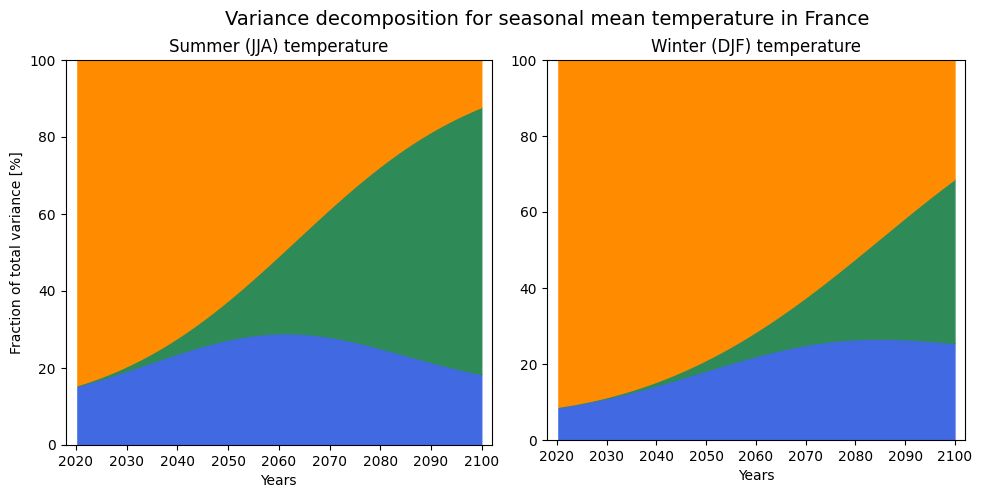

In [24]:
# Plot uncertainty decomposition
if len(fig.axes) == 1:
    ax = fig.add_axes( (1,0.12,0.76,0.76) )

    # plot fraction
    U_mod = 100*M_fr_w/T_fr_w
    U_sce = 100*(M_fr_w + S_fr_w)/T_fr_w
    U_var = 100*(M_fr_w + S_fr_w + V_fr_w)/T_fr_w

    ax.fill_between( ssp126['ts_fr_s']['year'], U_mod, np.zeros_like(M_fr_w), color='royalblue')
    ax.fill_between( ssp126['ts_fr_s']['year'], U_sce, U_mod,                 color='seagreen')
    ax.fill_between( ssp126['ts_fr_s']['year'], U_var, U_sce,                 color='darkorange')

    #
    ax.set_ylim((0,100))
    ax.set_xlim((2018, 2102))
    ax.fill_between( [2018, 2020], [100, 100], [0, 0],  color='white')
    ax.set_xlabel('Years')
    
    fig.axes[0].set_title(r"Summer (JJA) temperature")
    ax.set_title(r"Winter (DJF) temperature",)

fig.suptitle("Variance decomposition for seasonal mean temperature in France", fontsize=14, x=1)
fig

<font color="blue">

France winter temperature seems really noisy so that the internal variability leads the uncertainty; even in 2100 it accounts for ~40% of the total uncertainty. why ? 
    
We can note that scenario seems less important in winter than summer; why ?     
    
</font>

<a id="section-4"></a>
## 4. Projection of extreme temperature

In the previous sections, we focused on the projection of mean temperature and precipitation changes. However, extreme events are also affected by climate change. Here, we illustrate this by analysing a time-serie of daily temperature.

The following code loads the projection of daily maximum temperature, averaged over the western Europe domain, and using CNRM-CM6-1 following the SSP5-8.5:

```python
# load netCDF file
ds = xr.load_dataset(
    '../data/CNRM-CM6-1/tasmax_day_CNRM-CM6-1_ssp585_r1i1p1f2_WEU_20150101-21001231.nc', use_cftime=True
)
ssp585['tasmax'] = ds['tasmax']
```

#### Question 12

* _Load the dataset and plot the projection of summer (JJA) maximal temperature in western Europe_.
* _Does the regional projection of maximal follow the global and regional yearly global mean ?_

__Help:__ use the [xarray.groupby](https://docs.xarray.dev/en/stable/generated/xarray.DataArray.groupby.html) function with `'time.season'` to select June, July and August (JJA) months only.

In [25]:
# load netCDF file
ds = xr.load_dataset(
    '../data/CNRM-CM6-1/tasmax_day_CNRM-CM6-1_ssp585_r1i1p1f2_WEU_20150101-21001231.nc', use_cftime=True
)
ssp585['tasmax'] = ds['tasmax']-273.15

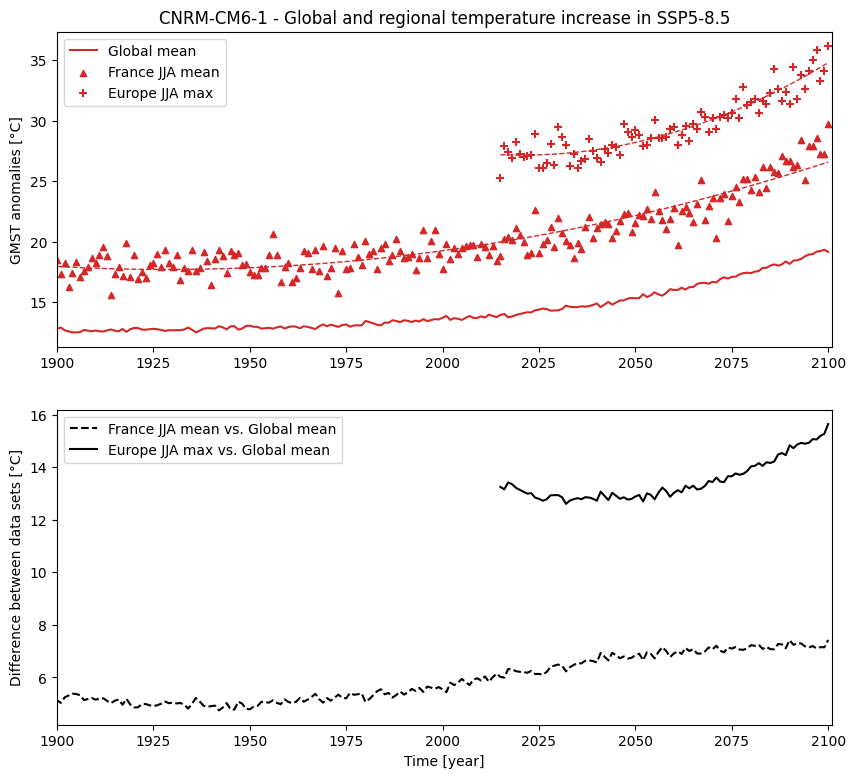

In [26]:
# plot
fig, axes = plt.subplots(2,1, figsize=(10, 9))

ax  = axes[0]
axd = axes[1] 

# choose one model
model = 'CNRM-CM6-1'

# plot global time-serie
times = ssp585['ts']['year']
ax.plot( times, ssp585['ts'].sel({'model': model}),  label='Global mean', lw=1.5, c='tab:red')

# plot France JJA time-serie
times = ssp585['ts_fr_s']['year']

coefs = np.polyfit( times, ssp585['ts_fr_s'].sel({'model': model}), deg=2)

ax.scatter( times, ssp585['ts_fr_s'].sel({'model': model}), label='France JJA mean', s=20, marker='^', c='tab:red')
ax.plot(    times, np.polyval(coefs, times), ls='--', lw=1., c='tab:red')

diff   = np.polyval(coefs, times) - ssp585['ts'].sel({'model': model})
axd.plot( times, diff , label='France JJA mean vs. Global mean', ls='--', c='k')

# plot western Europe JJA max time-serie
tmax_jja  = ssp585['tasmax'].groupby('time.season')['JJA']
tmax_year = tmax_jja.groupby('time.year').max()
times     = tmax_year['year']

coefs     = np.polyfit( times, tmax_year, deg=2)

ax.scatter( times, tmax_year, label='Europe JJA max', s=35, marker='+', lw=1.5, c='tab:red')
ax.plot(    times, np.polyval(coefs, times), ls='--', lw=1., c='tab:red')

diff   = np.polyval(coefs, times) - ssp585['ts'].sel({'model': model})[-86:]
axd.plot( times, diff , label='Europe JJA max vs. Global mean', ls='-', c='k')

# axe properties
ax.set_ylabel(r'GMST anomalies [°C]')
ax.set_xlim((1900, 2101))

axd.set_ylabel('Difference between data sets [°C]')
axd.set_xlabel('Time [year]')
axd.set_xlim((1900, 2101))


ax.legend(loc=2)
axd.legend(loc=2)

_ = ax.set_title("{} - Global and regional temperature increase in SSP5-8.5".format(model))

<font color="blue">

To a first order, the regional temperature projections (France and Europe) follow the global warming. 
Same for the maximal values.
    
However, the maximal seems to increase faster after year 2050.
    
</font>

#### Question 13

* _Plot the distribution of daily maximal temperature for three different periods (e.g. 2015-2035, 2035-2055 and 2080-2100)_.
* _Compute metrics to quantify how the distributions are projecting to change during the 21th century._ 

__Help:__ use of xarray sel function

In [41]:
stats_ssp5 = dict()
periods    = [('2015-01-01', '2035-01-01'), ('2035-01-01', '2055-01-01'), ('2080-01-01', '2100-01-01')]

for p in periods:
    
    # select data
    t_sel   = ssp585['tasmax'].sel({'time': slice(*p)}).groupby('time.season')['JJA']    
    
    # split in bins and count occurences
    probs, bins = np.histogram(t_sel, bins=51, density=True)

    stats_ssp5[p] = dict()
    stats_ssp5[p]['probs'] = probs
    stats_ssp5[p]['bins']  = 0.5*(bins[1:]+bins[:-1])
    
    # compute quantiles
    q05, q10, q50, q90, q95 = np.quantile(t_sel, q=[0.05, 0.1, 0.5, 0.9, 0.95])
    
    stats_ssp5[p]['Q05']  = q05
    stats_ssp5[p]['Q10']  = q10
    stats_ssp5[p]['Q50']  = q50
    stats_ssp5[p]['Q90']  = q90
    stats_ssp5[p]['Q95']  = q95


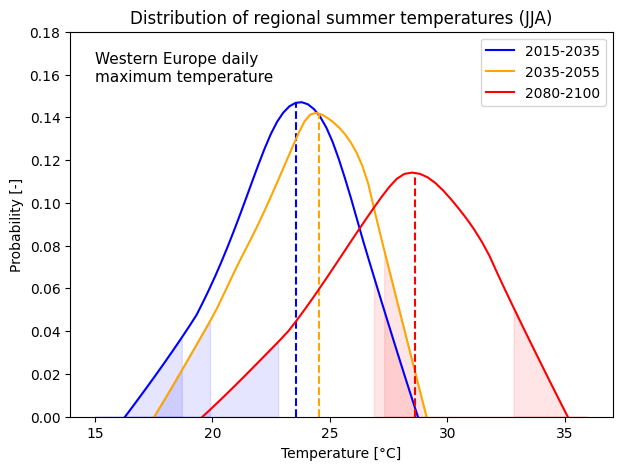

In [54]:
import statsmodels.api as sm

colors = ['blue', 'orange', 'red']

# create figure
fig, ax = plt.subplots(1,1, figsize=(7, 5))

for i, p in enumerate(stats_ssp5):
    
    bins  = stats_ssp5[p]['bins']
    probs = stats_ssp5[p]['probs']

    # smoothed distrib
    dist  = sm.nonparametric.lowess(exog=bins, endog=probs,  frac=0.5)[:,1]
    
    # get quantiles and associated prob
    q05 = stats_ssp5[p]['Q05']
    q50 = stats_ssp5[p]['Q50']
    q95 = stats_ssp5[p]['Q95']
    
    p05, p50, p95 = np.interp([q05, q50, q95], bins, dist)

    # plot distrib and quantiles
    label = '{}-{}'.format(p[0].split('-')[0], p[1].split('-')[0])
    
    ax.plot(bins, dist, color=colors[i], label=label)    # smoothed distribution
    ax.plot([q50, q50], [0, p50], ls='--', c=colors[i])  # median
    
    x05 = np.arange(15, q05, 0.1)
    ax.fill_between(x05, np.interp(x05, bins, dist), color='blue', alpha=0.1) # 5% coldest temperature
    
    x95 = np.arange(q95, 36, 0.1)
    ax.fill_between(x95, np.interp(x95, bins, dist), color='red', alpha=0.1)  # 5% warmest temperature
    
# ax properties
ax.set_ylim((0, 0.18))
ax.set_ylabel('Probability [-]')
ax.set_xlabel('Temperature [°C]')

ax.legend()

ax.text(15, 0.157, "Western Europe daily\nmaximum temperature", fontsize=11)

_ = ax.set_title('Distribution of regional summer temperatures (JJA)')

<font color="blue">

- change in the median / mean that is shifted toward warmer temperature
- standard deviation is also affected for the warmest periods; not really in 2030-2050
- extreme are also shifted but in different ways: coldest temperatures probability follow the mean shift while warmest temperatures are almost not affected in the 2030-2050 period  
        
</font>

#### Question 14

* _select the warmest summer on the first period_.

__Help:__ use of xarray sel function

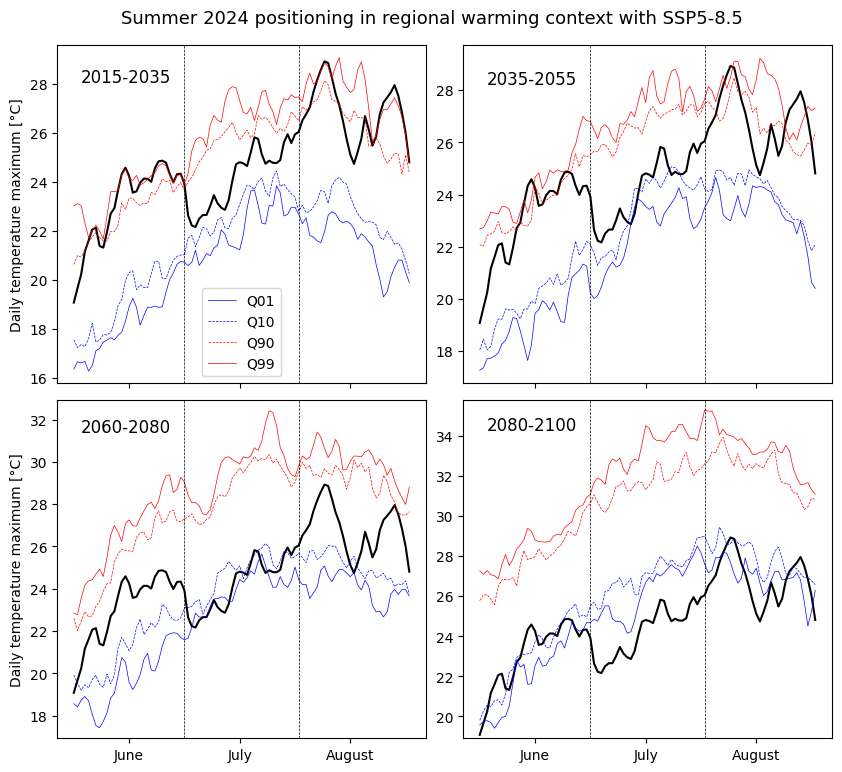

In [130]:
# create figure and axes
fig, axes = plt.subplots(2,2, figsize=(10, 9))
plt.subplots_adjust(wspace=0.1, hspace=0.05)

# select warmest summer in 2015-2025
t_sel  = ssp585['tasmax'].sel({'time': slice('2015-01-01', '2025-01-01')}).groupby('time.season')['JJA']
i_max  = int(t_sel.groupby('time.year').max().argmax())
t_warm = t_sel.groupby('time.year')[list(t_sel.groupby('time.year').groups)[i_max]]

# compute statistics in four different periods
periods = [('2015-01-01', '2035-01-01'), ('2035-01-01', '2055-01-01'), 
           ('2060-01-01', '2080-01-01'), ('2080-01-01', '2100-01-01')]

for i, p in enumerate(periods):
    
    # get axis
    ax = axes[i//2, i%2]
    
    # get temperatures for the period
    t_sel = ssp585['tasmax'].sel({'time': slice(*p)}).groupby('time.season')['JJA']
    
    # concatenate data for each year of the 20-year periods
    datas = []
    for y in list(t_sel.groupby('time.year').groups.keys()):
        datas.append(t_sel.groupby('time.year')[y])

    datas = np.vstack(datas)
    
    # compute percentile for each day of the summer
    p1, p10, p90, p99 = np.percentile(datas, [1, 10, 90, 99], axis=0)

    # plot time-series
    ax.plot(t_warm.groupby('time.year')[lyears[imax]], c='k')

    ax.plot(np.arange(92), p1,   lw=0.5, ls='-',  label='Q01', color='blue')
    ax.plot(np.arange(92), p10,  lw=0.5, ls='--', label='Q10', color='blue')

    ax.plot(np.arange(92), p90,  lw=0.5, ls='--', label='Q90', color='red')
    ax.plot(np.arange(92), p99,  lw=0.5, ls='-',  label='Q99', color='red')
    
    # split months
    ax.plot([30, 30], [np.min(p1)-0.5, np.max(p99)+0.5], ls='--', lw=0.5, c='k')
    ax.plot([61, 61], [np.min(p1)-0.5, np.max(p99)+0.5], ls='--', lw=0.5, c='k')

    ax.set_ylim((np.min(p1)-0.5, np.max(p99)+0.5))
    
    ax.text(2, np.max(p99)-1, '{}-{}'.format(p[0].split('-')[0], p[1].split('-')[0]), fontsize=12)
    

for i in range(len(periods)):
    ax = axes[i//2, i%2]
    ax.set_xticks([15, 45, 75])
    
    if i//2==0:
        ax.set_xticklabels([])
        if i%2==0:
            ax.legend(loc=8)
    else:
        ax.set_xticklabels(['June', 'July', 'August'])
        
    if i%2==0:
        ax.set_ylabel('Daily temperature maximum [°C]')

yr = list(t_warm.groupby('time.year').groups.keys())[0]
_  = fig.suptitle("Summer {} positioning in regional warming context with SSP5-8.5".format(yr), 
                y=0.92, fontsize=13)

<font color="blue">

- the warmest 'present-day' summer occurs in 2024
- this year is still particularly warm and rare in 2050 (peaks in the 99th percentile in June and August);
- however, it becomes normal in 2070, with extremly cold temperature in July; the temperature became an extreme cold event in 2100.. 
    
Note however, the method is not perfect here (only one model, one member and one scenario)
        
</font>

#### Going further (optional)

In the previous sections, we have decomposed the uncertainty in the temperature and precipitation projections. In particular, we have adressed how the fraction of each uncertainty is altered when changing variable and spatial and temporal scales.
However, there are still topics to explore if wanted. Among other:

* _For now, we have mainly explored the projection of integrated variables (e.g. global/regional temperature and precipitation mean). This integration can hide local changes that can differ from one region to another. You can ask for 2D data sets to investigate regional patterns._
* _The internal variability was considered constant and derived from forced simulations. How better estimations of the internal variability would alter the results ?_
* _There are plenty of variables that are simulated by general circulation models, you can ask fo any ideas or wishes that is able to satisfy your curiosity !_

## 5. Conclusion and discussion


#### Question 15

* _Propose a summary and conclusion of the notebook._ 

<font color="blue">

Conclusion should include:
    
  - short presentation of the lecture (simulations used here, for what purposes, etc.)
  - method and main results
  - discussion (uncertainty, limitations, how to reduce these limitations, etc.)
  - conclusion (e.g. what have they learned during the lecture)

</font>